In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
df = pd.read_csv('data/kits23_tumor_instance_data.csv')
print(len(df))

560


,tumor_id,case_id,tumor_instance,kidney_instance,calculated_diameter_mm,spacing_z,spacing_y,spacing_x,position,invasion,radius_pts,approved_for_training
0,case_00000_t1,case_00000,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,31.20,0.5,0.919922,0.919922,Peripheral,Noninvasive,0.0,True
1,case_00001_t1,case_00001,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,18.06,0.5,0.798828,0.798828,NaN,NaN,NaN,True
2,case_00001_t2,case_00001,tumor_instance-2_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,25.34,0.5,0.798828,0.798828,NaN,NaN,NaN,True
3,case_00002_t1,case_00002,tumor_instance-1_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,49.03,1.0,0.939453,0.939453,NaN,NaN,NaN,True
4,case_00003_t1,case_00003,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,32.72,1.0,0.855469,0.855469,Peripheral,Noninvasive,1.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...
555,case_00586_t3,case_00586,tumor_instance-3_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,20.16,3.0,0.781250,0.781250,NaN,NaN,NaN,True
556,case_00586_t1,case_00586,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,20.73,3.0,0.781250,0.781250,NaN,NaN,NaN,True
557,case_00586_t2,case_00586,tumor_instance-2_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,27.98,3.0,0.781250,0.781250,NaN,NaN,NaN,True
558,case_00587_t1,case_00587,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,21.96,5.0,0.800781,0.800781,NaN,NaN,NaN,True


In [20]:
print(df['tumor_instance'].value_counts())
print()
print(df['kidney_instance'].value_counts())
print()
print(df['position'].value_counts())
print()
print(df['invasion'].value_counts())
print()
print(df['radius_pts'].value_counts())

tumor_instance
tumor_instance-1_annotation-1.nii.gz     488
tumor_instance-2_annotation-1.nii.gz      51
tumor_instance-3_annotation-1.nii.gz      12
tumor_instance-4_annotation-1.nii.gz       2
tumor_instance-5_annotation-1.nii.gz       1
tumor_instance-8_annotation-1.nii.gz       1
tumor_instance-7_annotation-1.nii.gz       1
tumor_instance-9_annotation-1.nii.gz       1
tumor_instance-10_annotation-1.nii.gz      1
tumor_instance-6_annotation-1.nii.gz       1
tumor_instance-1_annotation-2.nii.gz       1
Name: count, dtype: int64

kidney_instance
kidney_instance-1_annotation-1.nii.gz    293
kidney_instance-2_annotation-1.nii.gz    266
kidney_instance-3_annotation-1.nii.gz      1
Name: count, dtype: int64

position
Peripheral    126
Hilar          52
Central        44
Name: count, dtype: int64

invasion
Invasive         99
Semi-invasive    66
Noninvasive      57
Name: count, dtype: int64

radius_pts
2.0    95
1.0    80
0.0    47
Name: count, dtype: int64


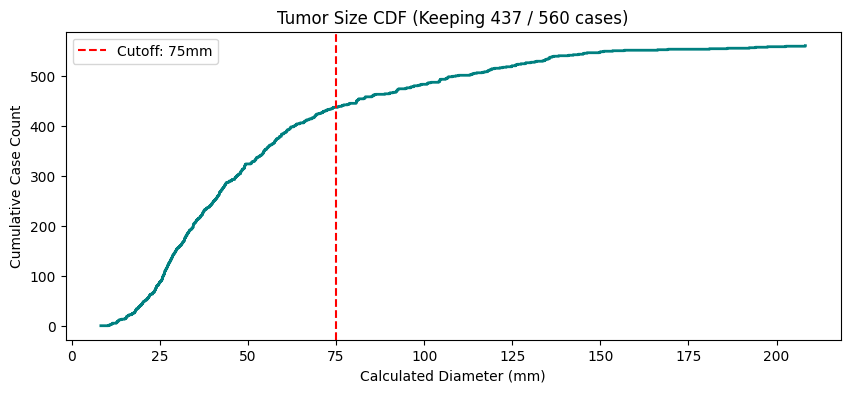

,tumor_id,case_id,tumor_instance,kidney_instance,calculated_diameter_mm,spacing_z,spacing_y,spacing_x,position,invasion,radius_pts,approved_for_training
0,case_00000_t1,case_00000,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,31.20,0.5,0.919922,0.919922,Peripheral,Noninvasive,0.0,True
1,case_00001_t1,case_00001,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,18.06,0.5,0.798828,0.798828,NaN,NaN,NaN,True
2,case_00001_t2,case_00001,tumor_instance-2_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,25.34,0.5,0.798828,0.798828,NaN,NaN,NaN,True
3,case_00002_t1,case_00002,tumor_instance-1_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,49.03,1.0,0.939453,0.939453,NaN,NaN,NaN,True
4,case_00003_t1,case_00003,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,32.72,1.0,0.855469,0.855469,Peripheral,Noninvasive,1.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...
555,case_00586_t3,case_00586,tumor_instance-3_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,20.16,3.0,0.781250,0.781250,NaN,NaN,NaN,True
556,case_00586_t1,case_00586,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,20.73,3.0,0.781250,0.781250,NaN,NaN,NaN,True
557,case_00586_t2,case_00586,tumor_instance-2_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,27.98,3.0,0.781250,0.781250,NaN,NaN,NaN,True
558,case_00587_t1,case_00587,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,21.96,5.0,0.800781,0.800781,NaN,NaN,NaN,True


In [21]:
def apply_threashold_and_plot(df, threshold):
    sorted_diameters = np.sort(df['calculated_diameter_mm'].dropna())
    y_vals = np.arange(1, len(sorted_diameters) + 1)

    # Plot CDF
    plt.figure(figsize=(10, 4))
    plt.step(sorted_diameters, y_vals, color='teal', where='post', linewidth=2)
    plt.axvline(x=threshold, color='red', linestyle='--', label=f'Cutoff: {threshold}mm')
    
    # Filter dataset
    kept_df = df[df['calculated_diameter_mm'] <= threshold].copy()
    
    plt.title(f"Tumor Size CDF (Keeping {len(kept_df)} / {len(df)} cases)")
    plt.xlabel("Calculated Diameter (mm)")
    plt.ylabel("Cumulative Case Count")
    plt.legend()
    plt.show()
    
    return kept_df

apply_threashold_and_plot(df, 75)